# Transformer 位置编码 · 第 1 讲
## 为什么需要位置编码？→ Sinusoidal Positional Encoding（2017）

> 学习顺序：**无位置编码的 Self-Attention → 问题定位 → Sinusoidal 的数学公式 → 从零实现 → 加入 Attention → 验证与思考**。

本节只学习原始 Transformer 的**固定正弦余弦位置编码**；`Learned Positional Embedding` 留到下一讲。

**完成本节后，你应该能够：**

1. 准确解释为什么**没有额外位置机制、没有 Mask 的 Self-Attention** 对输入顺序的置换是等变的。
2. 理解 `pos`、`i`、`d_model` 分别代表什么，为什么交替使用 `sin` 和 `cos`。
3. 自己写出生成 `(max_len, d_model)` 正余弦矩阵的 PyTorch 代码。
4. 知道位置编码加在何处：**Token Embedding + Position Encoding，然后才计算 Q/K/V**。
5. 理解它与之后的相对位置编码、RoPE 在数学上的联系。

参考论文：Vaswani et al., *Attention Is All You Need*（NeurIPS 2017），第 3.5 节。  
原论文：https://arxiv.org/abs/1706.03762

## 0. 回顾：Self-Attention 的输入是什么？

我们以三个 Token 为例：

```text
句子 A：苹果  很  甜
位置：   0    1   2

句子 B：甜    很  苹果
位置：   0    1   2
```

Token Embedding 解决的是：**“这个 Token 是什么？”**  
位置编码要补充的是：**“这个 Token 出现在什么位置？”**

先复习最基本的 Scaled Dot-Product Attention：

$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
$$

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

这里的 $X$ 只有 Token 的内容表示，尚未加入位置信息。

为了**只观察位置问题**，下面先取一种合法的简化情况：$W_Q=W_K=W_V=I$，也就是 $Q=K=V=X$。完整的共享线性投影也具有同样的置换等变性质。

In [2]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 使用固定的随机种子，让每次运行都能得到相同的实验结论。
torch.manual_seed(42)

def self_attention(x):
    """不使用位置编码 / 因果掩码的简单 Self-Attention。

    参数：
        x: (B, L, D)
           B: batch_size，L: 序列长度，D: 特征维度
    返回：
        out: (B, L, D)
        attn: (B, L, L)
    """
    # 简化为 Q = K = V = X，便于把注意力的顺序性质看清楚。
    q = k = v = x

    # (B, L, D) @ (B, D, L) -> (B, L, L)
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))

    # 每一行是一个 Query；每一列对应一个 Key。
    # 在 Key 维度归一化，使每行的注意力权重之和为 1。
    attn = torch.softmax(scores, dim=-1)

    # (B, L, L) @ (B, L, D) -> (B, L, D)
    out = attn @ v
    return out, attn

## 1. 实验：不加位置编码会发生什么？

我们创建一个只含三个 Token 的词表，并交换句子 A 中首尾两个 Token。

这一步想证明的是：对于**没有位置编码、没有位置 Mask** 的 Self-Attention，如果仅仅重排输入 Token，那么输出也只会跟着重排；对于同一个 Token，它的输出向量不会因为位置改变而改变。

术语是 **Permutation Equivariance（置换等变性）**，不是“所有输出完全一样”。

In [ ]:
# 假设我们的词表为：0=苹果，1=很，2=甜。
vocab = {"苹果": 0, "很": 1, "甜": 2}

# nn.Embedding 只按 Token ID 查表，不接收位置信息。
d_model = 8
embedding = nn.Embedding(num_embeddings=3, embedding_dim=d_model)

# 这两个中的词是一样的，只是词的顺序不同
ids_a = torch.tensor([[0, 1, 2]])  # 苹果 很 甜  -> (B=1, L=3)
ids_b = torch.tensor([[2, 1, 0]])  # 甜 很 苹果  -> (B=1, L=3)

x_a = embedding(ids_a)              # (1, 3, 8)
x_b = embedding(ids_b)              # (1, 3, 8)

out_a, attention_a = self_attention(x_a)
out_b, attention_b = self_attention(x_b)

# 因为句子 B 是按 [2, 1, 0] 重排句子 A，所以输出应该是相同的重排。
perm = [2, 1, 0]
# out_a[:, perm, :] = 把 out_a 里面每个 batch 内部的 token，按照 perm 索引调换顺序。
print('B 的输出 = A 的输出按同样顺序重排？',
      torch.allclose(out_b, out_a[:, perm, :], atol=1e-6))

# 苹果在句子 A 的第 0 位，在句子 B 的第 2 位。同一个 Token 虽然换了位置，对应的注意力结果却保持一致。
# torch.allclose：判断两个张量**逐元素近似相等；atol=1e-6 绝对误差容忍上限，浮点计算微小误差会被忽略，返回 True / False
print('苹果换了位置后表示相同？',
      torch.allclose(out_a[0, 0], out_b[0, 2], atol=1e-6))

print('句子 A 的 Attention Matrix：')
print(attention_a[0].detach().round(decimals=3))
print('句子 B 的 Attention Matrix：')
print(attention_b[0].detach().round(decimals=3))

B 的输出 = A 的输出按同样顺序重排？ True
苹果换了位置后表示相同？ True
句子 A 的 Attention Matrix：
tensor([[0.9940, 0.0020, 0.0040],
        [0.0320, 0.8450, 0.1230],
        [0.1840, 0.3850, 0.4310]])
句子 B 的 Attention Matrix：
tensor([[0.4310, 0.3850, 0.1840],
        [0.1230, 0.8450, 0.0320],
        [0.0040, 0.0020, 0.9940]])


### 1.1 为什么会这样？

令 $P$ 为“重新排列 Token”的置换矩阵，那么无位置机制、无 Mask 的 Self-Attention 满足：

$$
\boxed{\operatorname{Attention}(PX)=P\operatorname{Attention}(X)}
$$

重点是：

- **输出依然有序列维度**，并不是三个输出都变得一样；
- 但是只要我们同时移动 Token 和它对应的输出，就无法根据同一个 Token 的特征判断它原来处于第几个位置；
- 因此，模型需要一种机制，让“Token 的位置”参与计算。

> **容易混淆的地方：** Decoder 的 Causal Mask 会阻止 Token 看未来的 Token，本身带有方向性的结构约束，上述完整置换等变的证明就不再直接适用。但 **Causal Mask ≠ 位置编码**；它主要约束“能看谁”，并不等于为每个 Token 提供完整的位置表示。为了看清位置编码的作用，本节实验故意不使用 Causal Mask。

## 2. 最直接的思路：把“位置向量”加到“词向量”上

原始 Transformer 采用如下方式：

$$
\boxed{H=X+PE}
$$

其中：

- $X\in\mathbb{R}^{B\times L\times d_{model}}$：Token Embedding（简化表示）；
- $PE\in\mathbb{R}^{L\times d_{model}}$：每个位置对应的编码；
- $H\in\mathbb{R}^{B\times L\times d_{model}}$：加入位置信息后的表示。

位置编码会沿 Batch 维度广播。这样同一个 Token 在位置 0 和位置 2 时，虽然词向量相同，但加上的位置向量不同。

**与原论文严格对齐时：** 词嵌入先乘以 $\sqrt{d_{model}}$，再与位置编码相加；原论文还对这个和应用 Dropout。为了学习公式，下面的基础编码模块暂时不加 Dropout。

```text
Token IDs
   │
   ▼
Embedding ── × sqrt(d_model) ──┐
                               + ──> H ──> Linear ──> Q, K, V ──> Attention
Position indices ──> PE ──────┘
```

## 3. Sinusoidal Positional Encoding 的定义

2017 年的原始 Transformer 使用固定的正弦与余弦函数生成位置向量：

$$
\boxed{PE(pos,2i)=\sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)}
$$

$$
\boxed{PE(pos,2i+1)=\cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)}
$$

理解符号：

| 符号 | 含义 | 本节例子 |
|---|---|---|
| $pos$ | Token 在序列中的绝对位置，从 0 开始 | 0、1、2、… |
| $d_{model}$ | 每个 Token 的特征维度 | 8 |
| $i$ | 第几组 sin/cos 函数 | 0、1、2、3 |
| $2i$ | 第 $i$ 组中的偶数维度，使用 sin | 0、2、4、6 |
| $2i+1$ | 第 $i$ 组中的奇数维度，使用 cos | 1、3、5、7 |

注意：**并不是偶数位置用 sin、奇数位置用 cos，而是“特征的偶数维度用 sin、奇数维度用 cos”。**

当 $d_{model}=8$ 时：

$$
PE(pos)=[\sin(pos),\cos(pos),\sin(pos/10),\cos(pos/10),\sin(pos/100),\cos(pos/100),\sin(pos/1000),\cos(pos/1000)]
$$

不同维度使用不同频率：前面的维度变化更快，后面的维度变化更慢。每一对 sin/cos 一起描述对应频率下的位置。这里先使用偶数维度，方便 sin/cos 两两配对。

In [4]:
# 只用普通 Python 看清楚 d_model=8 时每一对维度对应的分母。
d_model = 8
for i in range(d_model // 2):
    denominator = 10000 ** (2 * i / d_model)
    print(f'i={i} | 对应维度 ({2*i}, {2*i+1}) | 分母={denominator:.0f}')

print('\n位置 pos=0 的编码一定是：[0,1,0,1,0,1,0,1]')

i=0 | 对应维度 (0, 1) | 分母=1
i=1 | 对应维度 (2, 3) | 分母=10
i=2 | 对应维度 (4, 5) | 分母=100
i=3 | 对应维度 (6, 7) | 分母=1000

位置 pos=0 的编码一定是：[0,1,0,1,0,1,0,1]


## 4. 不急着写类：先用 Tensor 一步一步构建 PE

目标是生成一个位置编码矩阵：

$$PE\in\mathbb{R}^{L\times d_{model}}$$

行对应位置，列对应特征维度。代码分成：① 生成位置，② 生成不同维度的角频率，③ 相乘得到角度，④ 偶数维度取 sin，奇数维度取 cos。

In [ ]:
# 假设序列最大长度只有 5，每个 Token 的特征维度是 8。
max_len = 5
d_model = 8

# 第一步：生成位置 [0,1,2,3,4]，转为列向量 (5,1)。.unsqueeze(1)：在第 1 维（维度索引从 0 开始）新增一维
# shape(5,)是一维张量，只有5个元素，不存在行列；(5,1)是二维张量，代表5行1列。
positions = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)

# 第二步：每组 sin/cos 的角频率 ω_i = 1 / 10000^(2i/d_model)。
# i = 0,1,2,3，得到的结果形状是 (4,)。
i = torch.arange(d_model // 2, dtype=torch.float32)
frequencies = 1.0 / (10000 ** (2 * i / d_model))

# 第三步：位置与角频率广播相乘。
# (5,1) * (4,) -> (5,4)，每个元素都是 pos * ω_i。
angles = positions * frequencies

# 第四步：准备存放位置编码的矩阵 (5,8)。
pe = torch.zeros(max_len, d_model)

# 偶数列 0,2,4,6 填 sin；奇数列 1,3,5,7 填 cos。
# 0::2 = 起始:终止:步长，省略终止代表一直到末尾。
pe[:, 0::2] = torch.sin(angles)
pe[:, 1::2] = torch.cos(angles)

print('positions.shape:', tuple(positions.shape))
print('frequencies.shape:', tuple(frequencies.shape))
print('angles.shape:', tuple(angles.shape))
print('pe.shape:', tuple(pe.shape))
print('\nPE 矩阵（每一行对应一个位置）：')
print(pe.round(decimals=4)) # 把位置编码张量`pe`里**每一个浮点数保留 4 位小数**再打印，用来简化查看，去掉一堆冗长小数。

tensor([0., 1., 2., 3., 4.])
positions.shape: (5, 1)
frequencies.shape: (4,)
angles.shape: (5, 4)
pe.shape: (5, 8)

PE 矩阵（每一行对应一个位置）：
tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0998,  0.9950,  0.0100,  1.0000,  0.0010,  1.0000],
        [ 0.9093, -0.4161,  0.1987,  0.9801,  0.0200,  0.9998,  0.0020,  1.0000],
        [ 0.1411, -0.9900,  0.2955,  0.9553,  0.0300,  0.9996,  0.0030,  1.0000],
        [-0.7568, -0.6536,  0.3894,  0.9211,  0.0400,  0.9992,  0.0040,  1.0000]])


### 4.1 检查矩阵有没有生成错

位置 0 时，所有角度都是 0，所以：

$$PE(0,2i)=\sin(0)=0,\quad PE(0,2i+1)=\cos(0)=1$$

另外，每组相邻维度构成 sin/cos，因此对任意位置、任意 $i$：

$$PE(pos,2i)^2+PE(pos,2i+1)^2=1$$

我们直接验证这两条性质。

In [8]:
# 第一条：位置 0 的偶数列全为 0，奇数列全为 1。
assert torch.allclose(pe[0, 0::2], torch.zeros(d_model // 2))
assert torch.allclose(pe[0, 1::2], torch.ones(d_model // 2))

# 第二条：每对 sin/cos 平方之和恒为 1。
pair_norm_squared = pe[:, 0::2] ** 2 + pe[:, 1::2] ** 2
assert torch.allclose(pair_norm_squared, torch.ones_like(pair_norm_squared), atol=1e-6)

print('检查通过：位置 0 的值正确，且每组 sin²+cos²=1。')

检查通过：位置 0 的值正确，且每组 sin²+cos²=1。


## 5. 封装成可以直接放进 Transformer 的模块

和 `nn.Embedding` 不同，固定 Sinusoidal PE **不需要训练位置参数**。

采用 `register_buffer` 的原因：

1. `pe` 是模型需要使用的 Tensor，但不是优化器需要更新的参数；
2. 调用 `.to(device)` 时，它会随模型移动设备；
3. 默认也能写入模型的 `state_dict`，方便保存与加载。

输入和输出都是 `(B, L, D)`。另加一个 `start_pos` 参数，便于将来理解 KV Cache 推理中的位置偏移。

In [ ]:
class SinusoidalPositionalEncoding(nn.Module):
    """原始 Transformer 使用的固定 sin/cos 位置编码（无 Dropout 版本）。"""

    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()

        if d_model <= 0 or d_model % 2 != 0:
            raise ValueError('实现要求 d_model 为正偶数，方便 sin/cos 配对。')
        if max_len <= 0:
            raise ValueError('max_len 必须为正整数。')

        # positions：(max_len, 1)，例如 [[0],[1],[2],...]
        positions = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)

        # 一共 d_model/2 组 sin/cos。相邻的sin/cos用的是同一个 i。2i只需要一半就可以解决全部维度。
        pair_indices = torch.arange(d_model // 2, dtype=torch.float32)

        # 每组角频率 ω_i = 10000^(-2i/d_model)
        # 直接做10000 ** x 会产生极小浮点数，容易触发浮点下溢；换成 exp(log(10000)*x)是在对数域先运算，GPU 浮点运算精度更可控，下溢风险更低。
        inv_freq = torch.exp(-math.log(10000.0) * (2 * pair_indices / d_model))

        
        # 同一组计算sin/cos都是用的 10000*（2i/d_model），输入是一样的，只是计算的函数不一样
        # 一次性把所有位置的角度计算出来，方便后续 sin/cos 计算。
        angles = positions * inv_freq # (max_len, 1) * (d_model/2,) -> (max_len, d_model/2)

        # pe的维度还是d_model，只是组数是d_model/2，每组有 sin/cos 两个维度。
        pe = torch.zeros(max_len, d_model, dtype=torch.float32)
        pe[:, 0::2] = torch.sin(angles) # 奇数做sin
        pe[:, 1::2] = torch.cos(angles) # 偶数做cos

        # 变成 (1, max_len, d_model)，以便与 Batch 维度广播相加。
        pe = pe.unsqueeze(0) # 里面数值没变，外面多包一层`[]`，代表 batch 这个维度长度是 1。

        # buffer 不属于可训练的 nn.Parameter。但是又是张量，所以注册为 buffer，方便在模型保存/加载时一并处理。前面的batchnorm也是这样的
        self.register_buffer('pe', pe)

    def forward(self, x: torch.Tensor, start_pos: int = 0) -> torch.Tensor:
        # 这里加 startpos 应该是为了 kvcache ，也就是推理的时候有位置信息
        # x: (B, L, D)，L 是这次输入的 Token 数量。
        if x.ndim != 3:
            raise ValueError('x 应为 (B, L, D) 三维 Tensor。')
        if x.size(-1) != self.pe.size(-1):
            raise ValueError('x 最后一维必须等于 d_model。')

        seq_len = x.size(1)
        if start_pos < 0 or start_pos + seq_len > self.pe.size(1):
            raise ValueError('start_pos 或序列长度超出了 max_len。')

        # 只取本次 Token 对应的绝对位置。
        # 如 start_pos=3，seq_len=2，就取位置 3 和位置 4。
        position_vectors = self.pe[:, start_pos:start_pos + seq_len, :]

        # 让位置向量与 x 保持相同的 device / dtype。
        position_vectors = position_vectors.to(device=x.device, dtype=x.dtype)

        # (B,L,D) + (1,L,D) -> (B,L,D)
        return x + position_vectors


position_encoding = SinusoidalPositionalEncoding(d_model=8, max_len=128)
# position_encoding.parameters()：取出这个位置编码模块里**所有需要梯度、可训练的参数 
# p.numel()：单个参数张量里面元素总个数
# sum(...)：累加全部可训练参数总量
print('可训练参数数量:', sum(p.numel() for p in position_encoding.parameters()))
print('已注册的 buffer:', list(dict(position_encoding.named_buffers()).keys()))
print('位置矩阵形状:', tuple(position_encoding.pe.shape))

可训练参数数量: 0
已注册的 buffer: ['pe']
位置矩阵形状: (1, 128, 8)


## 6. 加入 Attention，验证位置确实参与了计算

与前面的实验保持同一个词表、同一个 Embedding。此时，原始 Transformer 的输入写成，这里除$\sqrt{d_{model}}$跟公式里的效果一样：

$$H=\operatorname{Embedding}(TokenIDs)\sqrt{d_{model}}+PE$$

为了单独观察位置编码的效果，继续使用之前的简化 `self_attention`。只要替换输入 $X\to H$ 即可；真实 Transformer 会在此基础上经过学习到的 Q/K/V 投影。

我们先观察两个句子的“苹果”位置表示是否还一样，再看 Attention 的结果。

In [10]:
# 复用前面创建的 embedding 和 ids_a / ids_b。
# 原论文把词嵌入乘以 sqrt(d_model)，此处按原论文做。
scaled_a = embedding(ids_a) * math.sqrt(d_model)
scaled_b = embedding(ids_b) * math.sqrt(d_model)

# 两句话位置 0/1/2 对应的 PE 相同，但绑定的 Token 不同。
h_a = position_encoding(scaled_a)
h_b = position_encoding(scaled_b)

# '苹果' 在 A 的位置 0，在 B 的位置 2。
print('不加 PE，同一 Token 换位置后的词向量相同？',
      torch.allclose(scaled_a[0, 0], scaled_b[0, 2]))
print('加了 PE，同一 Token 换位置后的输入表示仍相同？',
      torch.allclose(h_a[0, 0], h_b[0, 2]))

# 分别执行 Attention。
out_no_pe_a, _ = self_attention(scaled_a)
out_no_pe_b, _ = self_attention(scaled_b)
out_pe_a, _ = self_attention(h_a)
out_pe_b, _ = self_attention(h_b)

print('\n不加 PE：重排后输出只是同步重排？',
      torch.allclose(out_no_pe_b, out_no_pe_a[:, perm, :], atol=1e-6))
print('加入 PE：是否仍然满足相同的重排关系？',
      torch.allclose(out_pe_b, out_pe_a[:, perm, :], atol=1e-6))

print('\n加入 PE 后，同一 Token 在两个位置上的 Attention 输出差异范数：',
      torch.norm(out_pe_a[0, 0] - out_pe_b[0, 2]).detach().item())

不加 PE，同一 Token 换位置后的词向量相同？ True
加了 PE，同一 Token 换位置后的输入表示仍相同？ False

不加 PE：重排后输出只是同步重排？ True
加入 PE：是否仍然满足相同的重排关系？ False

加入 PE 后，同一 Token 在两个位置上的 Attention 输出差异范数： 1.6948641538619995


**如何理解输出？**

- 不加 PE：我们将 Token 重新排列，Self-Attention 的输出也按同样顺序排列；
- 加入 PE：相同 Token 在不同位置叠加了不同的向量，原先的简单“同步重排”关系一般不再成立；
- 这并不代表一个**没有训练过的随机模型就理解了词序**。实验仅证明位置进入了输入表示与后续 Attention 计算，能否利用它学习语言结构还需要训练。

## 7. 可视化：为什么使用不同频率？

展示前 64 个位置、32 维位置编码矩阵。你会看到较靠前的维度变化更快，而较靠后的维度变化更慢。

不同频率组合在一起，可以让位置在多个时间尺度上产生区别。

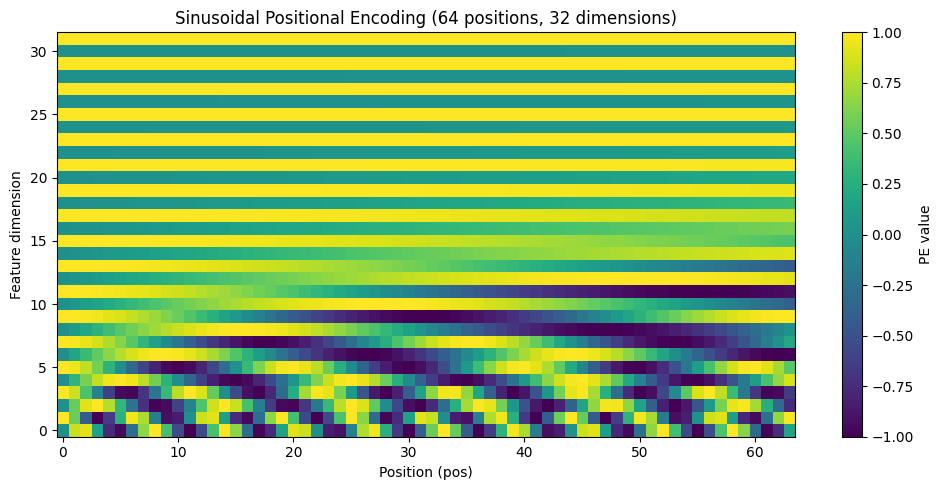

In [ ]:
visual_pe = SinusoidalPositionalEncoding(d_model=32, max_len=64).pe[0]
'''
这张热力图横轴代表 token 位置，纵轴是特征维度，颜色表示位置编码的数值；
图下方低维度的颜色横向交替很快，上方高维度颜色变化平缓，相邻两行波形错位，依靠不同频率的三角函数，给每个位置生成独有的向量标记。
'''
plt.figure(figsize=(10, 5))
plt.imshow(visual_pe.T.detach().numpy(), aspect='auto', origin='lower')
plt.xlabel('Position (pos)')
plt.ylabel('Feature dimension')
plt.title('Sinusoidal Positional Encoding (64 positions, 32 dimensions)')
plt.colorbar(label='PE value')
plt.tight_layout()
plt.show()

## 8. 一个很关键的性质：为什么 sin/cos 能表示相对距离？

先**只看第 $i$ 组的两个维度**。令：

$$\omega_i=10000^{-2i/d_{model}}$$

于是位置 $p$ 的这两个分量为：

$$v_i(p)=[\sin(p\omega_i),\cos(p\omega_i)]$$

位置 $q$ 的向量为：

$$v_i(q)=[\sin(q\omega_i),\cos(q\omega_i)]$$

用余弦差角公式：

$$
\begin{aligned}
v_i(p)\cdot v_i(q)
&=\sin(p\omega_i)\sin(q\omega_i)+\cos(p\omega_i)\cos(q\omega_i)\\
&=\boxed{\cos((p-q)\omega_i)}
\end{aligned}
$$

也就是说，在**纯位置向量**的这一对维度中，两位置的内积只与距离 $p-q$ 有关，即两个位置编码的相似度，**只看两个 token 隔多远，不看它们在句子的第几号**。全部维度的纯位置向量内积就是各组余弦的和。

**不要把这条结论误解成**“原始 Transformer 的 Attention Score 只与相对距离有关”。因为实际 $Q,K$ 由“Token 内容 + PE”投影而来，还存在内容以及内容与位置的交叉项。

这条性质会在后面学习**相对位置编码**和 **RoPE** 时再次出现。

In [ ]:
# 用数字验证差角公式，任选第 1 组（特征维度 2 和 5）。
p, q, i = 2, 5, 1
d_model = 8
omega = 10000 ** (-2 * i / d_model)

enc = SinusoidalPositionalEncoding(d_model=8, max_len=16)
pair_p = enc.pe[0, p, 2*i:2*i+2] # 取出p的这一组2个维度：2*i 和 2*i+1（偶数sin，奇数cos）
pair_q = enc.pe[0, q, 2*i:2*i+2]
# LHS：直接算两个二维向量的点积（内积)
lhs = torch.dot(pair_p, pair_q)
# RHS：用三角公式直接计算理论结果
rhs = math.cos((p - q) * omega)

print('sin/cos 两维向量的内积：', float(lhs))
print('cos((p-q) * omega) ：', rhs)
assert math.isclose(float(lhs), rhs, abs_tol=1e-6)

sin/cos 两维向量的内积： 0.9553365111351013
cos((p-q) * omega) ： 0.955336489125606


正弦位置编码为序列中每个token的位置生成特征向量，以两个维度为一组构造 $[\sin(p\omega_i),\cos(p\omega_i)]$ 单位圆向量。
借助三角差角公式，同组位置编码的内积仅取决于位置差值，天然适配自注意力依靠内积衡量token相似度的逻辑。

角频率 $\omega_i=10000^{-2i/d_{model}}$ 采用指数衰减设计：
$2i$ 用于对sin/cos成对分组，除以 $d_{model}$ 绑定频率与模型维度；
$i$ 越小，$\omega_i$ 越大（高频），波形震荡快，位置微小变动就会带来明显数值变化，用于区分相邻token；
$i$ 越大，$\omega_i$ 越小（低频），波形变化平缓、周期很长，远距离范围内不容易发生三角函数循环混叠，用来识别相隔很远的token。

(说白了就是，想让他一个周期尽量多的表示位置，近的是因为i小，所以变化才快)

将多组不同频率的向量拼接得到完整位置编码。
该编码预先固定无需训练，还可以外推处理训练阶段未见过的更长序列。

如果直接使用固定频率或者线性变化频率，会缺少这种多尺度分工：
固定频率只有单一变化速度，无法同时兼顾近距离和远距离位置识别；
频率随i线性增大的方案，高组别高频震荡过快，容易发生位置混叠，缺少足够的超低频分量捕捉长距离信息。


## 9. 与 KV Cache 的联系：为什么要保留 `start_pos`？

假设前面已经处理了 3 个 Token，现在只计算新增的 2 个 Token。

```text
全局位置： 0    1    2   |  3    4
         之前的 Token  |  新增 Token

新增输入长度 L=2，但它们的绝对位置是 3 和 4，不是 0 和 1。
```

所以推理时需要用正确的绝对位置取 PE。这里不涉及缓存实现，只验证位置索引。

In [ ]:
# 设新增的两个 Token 的词向量都为 0，这样输出就等于对应的 PE。
new_tokens_x = torch.zeros(1, 2, 8) # (B,L,dmodel)

# start_pos=3：对应全局位置 3、4。
# 调用正余弦位置编码，把新 Token 的词向量加上对应的 PE。
new_h = position_encoding(new_tokens_x, start_pos=3)
print(new_h.round(decimals=4)) # 保留 4 位小数，方便查看
# tensor([[[ 0.1411, -0.9900,  0.2955,  0.9553,  0.0300,  0.9996,  0.0030,
#           1.0000],
#         [-0.7568, -0.6536,  0.3894,  0.9211,  0.0400,  0.9992,  0.0040,
#           1.0000]]])

assert torch.allclose(new_h[0, 0], position_encoding.pe[0, 3])
assert torch.allclose(new_h[0, 1], position_encoding.pe[0, 4])

print('当前输入形状：', tuple(new_tokens_x.shape))
print('使用的绝对位置：3、4')
print('实际 PE 与位置 3、4 一致：True')

tensor([[[ 0.1411, -0.9900,  0.2955,  0.9553,  0.0300,  0.9996,  0.0030,
           1.0000],
         [-0.7568, -0.6536,  0.3894,  0.9211,  0.0400,  0.9992,  0.0040,
           1.0000]]])
当前输入形状： (1, 2, 8)
使用的绝对位置：3、4
实际 PE 与位置 3、4 一致：True


## 10. 本讲总结 + 自检

### 你现在应该记住四件事

1. **Self-Attention 的核心是内容间的相似度。** 在没有任何位置信息与位置 Mask 的情况下，重排输入只会重排输出，不能凭同一个 Token 的表示区分它处在哪个位置。
2. **Sinusoidal 是固定绝对位置编码。** 每个位置映射成一个 $d_{model}$ 维向量；偶数**特征维度**用 sin，奇数特征维度用 cos。
3. **位置编码是在 Q/K/V 投影之前加入的。** 原论文的形式是 $Embedding\times\sqrt{d_{model}}+PE$，随后再计算 Attention。
4. **不同频率是关键。** 单个 sin/cos 维度有周期性，多组不同频率一起提供多尺度的位置表示；纯位置分量之间的内积有相对距离性质。

### 三个自检问题

1. `d_model=8` 时，为什么 PE 的形状是 `(L, 8)`，而不是 `(L, 4)`？
2. 同一个 `苹果` 分别出现在位置 0 和位置 2：Token Embedding 变了吗？PE 变了吗？
3. KV Cache 推理时新增的 2 个 Token 对应位置 5、6，为什么不能从位置 0 重新编码？

<details>
<summary>展开参考答案</summary>

1. 一共有 4 **组** sin/cos，每组占 2 **维**，总共 8 维。
2. 若使用同一嵌入表，Token Embedding 不变；绝对位置不同，PE 发生变化，二者之和随之改变。
3. 新 Token 在完整序列中的绝对索引是 5、6，使用位置 0、1 会把位置编码错误地重置。

</details>

**下一讲：Learned Positional Embedding。** 研究一个新问题——既然 sin/cos 可以固定生成位置向量，为什么不直接让模型**学习每个位置的向量**？这样做有什么优势与限制？